# This is a workflow to query and visualize FIRMS (real-time fire) data.

Below, please enter your map key to gain access to the API. You can get one <span style='color:blue'>[here](https://firms.modaps.eosdis.nasa.gov/api/map_key/)</span>

In [1]:
import pandas as pd
import cartopy
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.insert(0,"/home/jovyan/shared/Libraries")
import victor

MAP_KEY = 'adedf1a21791fe0e126299ba9dab98f0'

### For reference, we display the various satellites and their accessible date ranges.

In [2]:
da_url = 'https://firms.modaps.eosdis.nasa.gov/api/data_availability/csv/' + MAP_KEY + '/all'
df = pd.read_csv(da_url)
display(df)

area_url = 'https://firms.modaps.eosdis.nasa.gov/api/area/csv/' + MAP_KEY + '/VIIRS_NOAA20_NRT/54,5.5,102,40/3'
df_area = pd.read_csv(area_url)
df_area

,data_id,min_date,max_date
0,MODIS_NRT,2026-03-01,2026-06-05
1,MODIS_SP,2000-11-01,2026-02-28
2,VIIRS_NOAA20_NRT,2026-04-01,2026-06-05
3,VIIRS_NOAA20_SP,2018-04-01,2026-03-31
4,VIIRS_NOAA21_NRT,2024-01-17,2026-06-05
5,VIIRS_SNPP_NRT,2026-04-01,2026-06-05
6,VIIRS_SNPP_SP,2012-01-20,2026-03-31
7,LANDSAT_NRT,2022-06-20,2026-06-05
8,GOES_NRT,2022-08-09,2026-06-05
9,BA_MODIS,2000-11-01,2026-03-01


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight
0,5.73945,101.89190,328.44,0.50,0.49,2026-06-03,610,N20,VIIRS,n,2.0NRT,293.11,4.68,D
1,5.74180,101.88908,328.95,0.50,0.49,2026-06-03,610,N20,VIIRS,n,2.0NRT,293.31,5.65,D
2,6.25207,101.51255,336.24,0.52,0.50,2026-06-03,612,N20,VIIRS,n,2.0NRT,292.44,7.83,D
3,12.85096,99.94833,339.89,0.51,0.50,2026-06-03,614,N20,VIIRS,n,2.0NRT,290.42,5.65,D
4,13.09686,101.26385,335.09,0.42,0.45,2026-06-03,614,N20,VIIRS,n,2.0NRT,294.59,6.63,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4451,37.92079,65.11148,344.75,0.38,0.43,2026-06-05,905,N20,VIIRS,n,2.0NRT,313.43,3.82,D
4452,39.18591,63.40639,350.05,0.50,0.41,2026-06-05,905,N20,VIIRS,n,2.0NRT,317.79,16.66,D
4453,39.18656,63.41213,337.64,0.50,0.41,2026-06-05,905,N20,VIIRS,l,2.0NRT,311.90,10.32,D
4454,39.18964,63.40571,347.15,0.50,0.41,2026-06-05,905,N20,VIIRS,n,2.0NRT,317.04,16.66,D


### Now, a few simple values are required to get the data.

In [44]:
# Bounds: Enter in the format min_long, max_long, min_lat, mat_lat
bounds = [-22.6,-21.9,63.7, 63.9]

# Number of days previous to poll
days = 5

# Start date - YYYY-MM-DD format. Leave as none to start from current day
date = "2024-06-01"

In [45]:
area_url = 'https://firms.modaps.eosdis.nasa.gov/api/area/csv/' + MAP_KEY + f'/VIIRS_NOAA21_NRT/{bounds[0]},{bounds[2]},{bounds[1]},{bounds[3]}/{days}/'
if date is not None:
    area_url += date
area_url

'https://firms.modaps.eosdis.nasa.gov/api/area/csv/adedf1a21791fe0e126299ba9dab98f0/VIIRS_NOAA21_NRT/-22.6,63.7,-21.9,63.9/5/2024-06-01'

In [46]:
data = victor.get_firms_data(MAP_KEY, bounds, days, date)

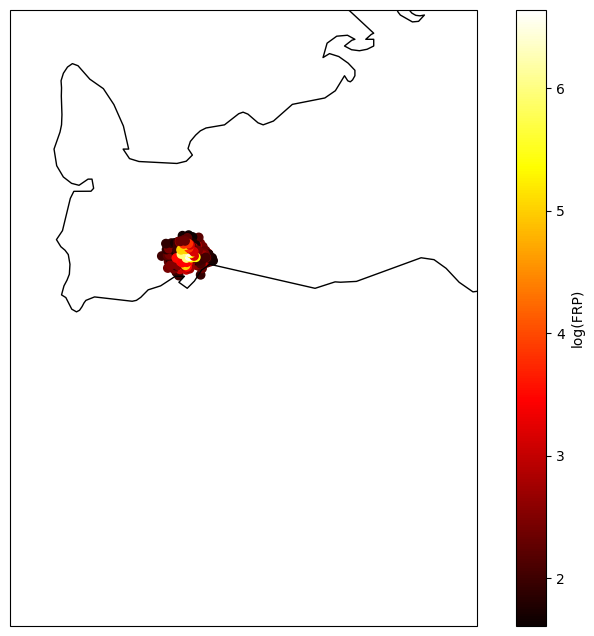

In [53]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# bounds = [min_lon, max_lon, min_lat, max_lat]

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.Mercator())

# Set map extent
ax.set_extent([
    bounds[0] - .25,  # min lon
    bounds[1] + .25,  # max lon
    bounds[2] - .25,  # min lat
    bounds[3] + .25   # max lat
], crs=ccrs.PlateCarree())

# Coastlines and country borders
ax.coastlines()
ax.add_feature(cfeature.BORDERS)

# Scatter plot
sc = ax.scatter(
    data.longitude,
    data.latitude,
    # s=data.frp,                 # marker size
    c=np.log(data.frp),         # marker color
    cmap="hot",
    transform=ccrs.PlateCarree()
)

plt.colorbar(sc, ax=ax, label="log(FRP)")
plt.show()

In [27]:
url = 'https://firms.modaps.eosdis.nasa.gov/mapserver/mapkey_status/?MAP_KEY=' + MAP_KEY
def get_transaction_count(url) :
  count = 0
  try:
    df = pd.read_json(url,  typ='series')
    count = df['current_transactions']
  except:
    print ("Error in our call.")
  return count

tcount = get_transaction_count(url)
print ('Our current transaction count is %s' % tcount)

Our current transaction count is 1970-01-01 00:00:00.000130
